# MonsoonWatch — explainable next-day heavy-rainfall warning for Sri Lanka

This notebook runs the whole pipeline in order and shows the outputs used in the report. Each step calls the script in `src/`, so the notebook and the scripts always agree.

In [1]:
import sys, json, pandas as pd
from pathlib import Path
from IPython.display import Image, display
sys.path.insert(0, str(Path('..') / 'src'))
import config, data_prep, train, evaluate, explain, export_app_assets
FIG = config.FIG_DIR

## 1. Data: quality checks, de-duplication, features, time split

In [2]:
raw = data_prep.load_raw()
print(raw.shape)
raw.head()

(147480, 19)


,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,shortwave_radiation_sum,precipitation_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,city
0,2010-01-01,1,29.9,22.5,26.0,33.0,24.4,28.2,21.02,0.0,0.0,17.9,37.8,20,4.89,6.900002,79.899994,27.0,Athurugiriya
1,2010-01-02,1,30.0,23.3,26.1,32.9,25.4,29.0,17.98,0.0,0.0,17.7,36.0,20,4.09,6.900002,79.899994,27.0,Athurugiriya
2,2010-01-03,51,29.5,22.9,25.8,33.3,25.6,29.1,18.05,0.2,1.0,16.6,34.9,16,3.83,6.900002,79.899994,27.0,Athurugiriya
3,2010-01-04,3,28.7,21.7,25.2,31.5,23.0,27.5,18.46,0.0,0.0,18.2,38.2,4,4.12,6.900002,79.899994,27.0,Athurugiriya
4,2010-01-05,1,28.0,21.1,24.4,30.0,22.6,25.8,23.54,0.0,0.0,17.4,36.0,3,5.04,6.900002,79.899994,27.0,Athurugiriya


In [3]:
data_prep.main()

{
  "quality_checks": {
    "rows": 147480,
    "cities": 30,
    "date_min": "2010-01-01",
    "date_max": "2023-06-17",
    "missing_values": 0,
    "negative_rain": 0,
    "tmin_above_tmax": 0,
    "date_gaps": 0,
    "cities_after_dedup": 15,
    "rows_after_dedup": 73740,
    "merged_duplicate_cities": {
      "Gampaha": [
        "Athurugiriya",
        "Kolonnawa",
        "Mabole",
        "Negombo",
        "Oruwala",
        "Sri Jayewardenepura Kotte"
      ],
      "Colombo": [
        "Bentota",
        "Kalutara",
        "Kesbewa",
        "Maharagama",
        "Moratuwa",
        "Mount Lavinia"
      ],
      "Galle": [
        "Matara",
        "Weligama"
      ],
      "Kurunegala": [
        "Pothuhera"
      ]
    }
  },
  "modelling_rows": 73530,
  "n_features": 23,
  "categorical": [
    "weathercode"
  ],
  "split": {
    "train": {
      "rows": 54585,
      "from": "2010-01-14",
      "to": "2019-12-31",
      "heavy_rain_rate": 0.056
    },
    "valid": {
   

## 2. Training
`quick=True` reuses the EBM settings found by the grid search (saved in `models/model_meta.json`). Run `python src/train.py` to repeat the full search.

In [4]:
pd.read_csv(config.RESULTS_DIR / 'ebm_hyperparameter_search.csv')

,interactions,learning_rate,max_leaves,valid_pr_auc,valid_roc_auc,fit_seconds
0,20,0.02,2,0.2849,0.8583,11.9
1,20,0.05,3,0.2838,0.8581,5.1
2,20,0.02,3,0.2822,0.8584,5.0
3,20,0.05,2,0.2809,0.8585,6.3
4,10,0.05,2,0.2806,0.8600,5.4
5,10,0.02,2,0.2802,0.8596,12.3
6,10,0.02,3,0.2802,0.8586,5.4
7,10,0.05,3,0.2801,0.8589,4.1
8,0,0.02,2,0.2734,0.8590,14.6
9,0,0.05,2,0.2731,0.8596,5.8


In [5]:
train.main(quick=True)

EBM settings: {'interactions': 20, 'learning_rate': 0.02, 'max_leaves': 2}


EBM (proposed) {'threshold': 0.1557315771720918, 'valid_f1': 0.356, 'valid_pr_auc': 0.2868, 'valid_roc_auc': 0.8585, 'fit_seconds': 42.8}


Logistic Regression {'threshold': 0.1414992244900701, 'valid_f1': 0.3482, 'valid_pr_auc': 0.2617, 'valid_roc_auc': 0.8591, 'fit_seconds': 0.2}


Random Forest {'threshold': 0.1578940740571043, 'valid_f1': 0.3555, 'valid_pr_auc': 0.2842, 'valid_roc_auc': 0.8559, 'fit_seconds': 12.3}


LightGBM {'threshold': 0.151924333299836, 'valid_f1': 0.354, 'valid_pr_auc': 0.2755, 'valid_roc_auc': 0.861, 'fit_seconds': 1.6}


## 3. Evaluation on the 2022–23 test set

In [6]:
evaluate.main()
pd.read_csv(config.RESULTS_DIR / 'model_comparison.csv')

PR-AUC gain of EBM over Logistic Regression: 0.032 (95% CI 0.012 to 0.054)


PR-AUC gain of EBM over Random Forest: 0.032 (95% CI 0.017 to 0.049)


PR-AUC gain of EBM over LightGBM: 0.025 (95% CI 0.011 to 0.041)
                                      Model  ROC-AUC  PR-AUC     F1  Precision  Recall  Accuracy  Balanced acc.  Brier  Threshold ROC-AUC 95% CI PR-AUC 95% CI
                             EBM (proposed)   0.8525  0.2354 0.3450     0.2664  0.4894    0.9015         0.7070 0.0446     0.1557    0.836-0.868   0.205-0.275
                        Logistic Regression   0.8361  0.2040 0.3150     0.2233  0.5343    0.8768         0.7151 0.0461     0.1415    0.818-0.854   0.178-0.236
                              Random Forest   0.8438  0.2037 0.3037     0.2307  0.4444    0.8920         0.6807 0.0455     0.1579    0.825-0.860   0.177-0.235
                                   LightGBM   0.8432  0.2102 0.2989     0.2423  0.3901    0.9030         0.6609 0.0460     0.1519    0.827-0.861   0.182-0.244
Persistence (heavy today -> heavy tomorrow)      NaN     NaN 0.2220     0.2217  0.2222    0.9174         0.5893    NaN        NaN            

,Model,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,Balanced acc.,Brier,Threshold,ROC-AUC 95% CI,PR-AUC 95% CI
0,EBM (proposed),0.8525,0.2354,0.3450,0.2664,0.4894,0.9015,0.7070,0.0446,0.1557,0.836-0.868,0.205-0.275
1,Logistic Regression,0.8361,0.2040,0.3150,0.2233,0.5343,0.8768,0.7151,0.0461,0.1415,0.818-0.854,0.178-0.236
2,Random Forest,0.8438,0.2037,0.3037,0.2307,0.4444,0.8920,0.6807,0.0455,0.1579,0.825-0.860,0.177-0.235
3,LightGBM,0.8432,0.2102,0.2989,0.2423,0.3901,0.9030,0.6609,0.0460,0.1519,0.827-0.861,0.182-0.244
4,Persistence (heavy today -> heavy tomorrow),NaN,NaN,0.2220,0.2217,0.2222,0.9174,0.5893,NaN,NaN,NaN,NaN
5,Always 'no heavy rain',NaN,NaN,0.0000,NaN,0.0000,0.9470,0.5000,NaN,NaN,NaN,NaN


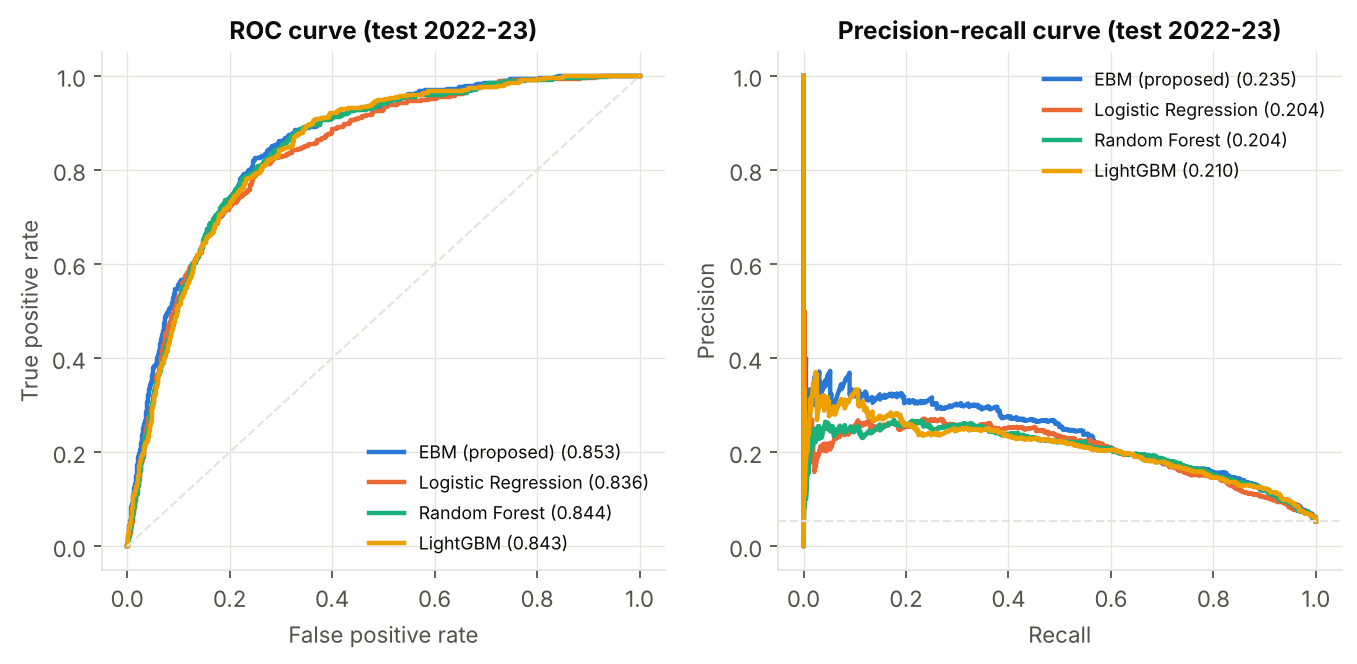

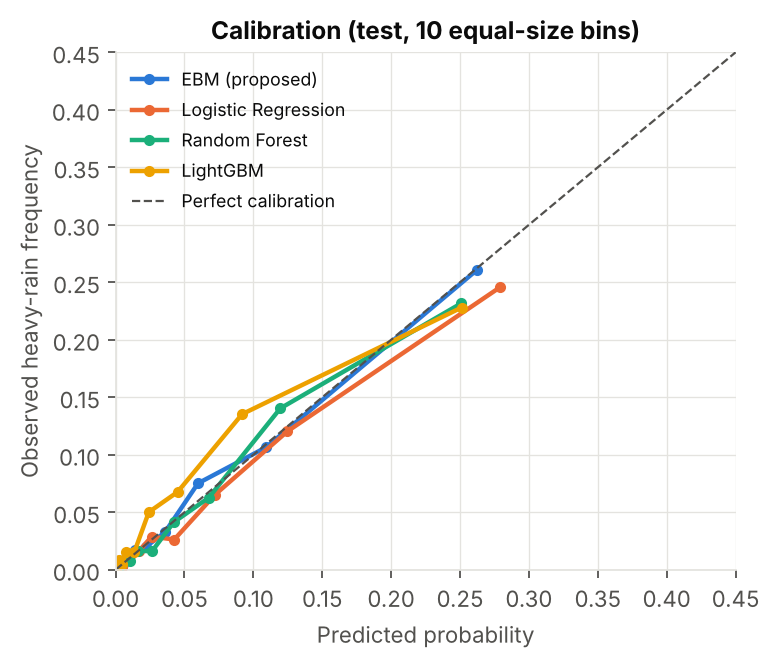

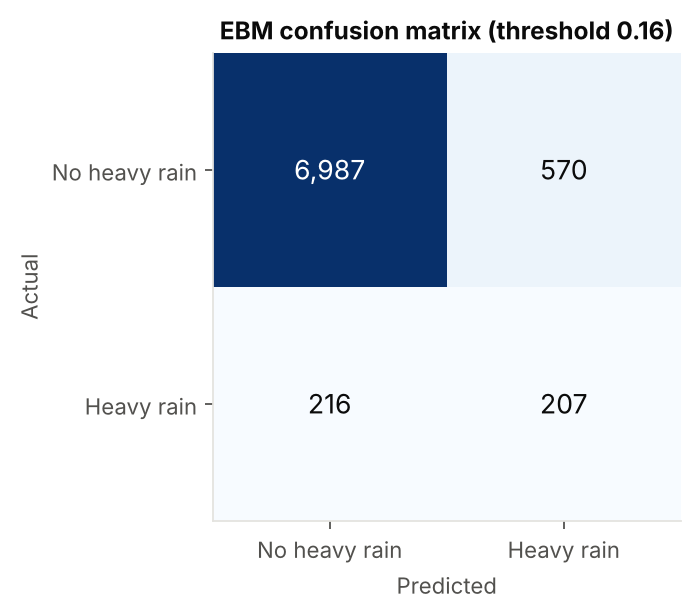

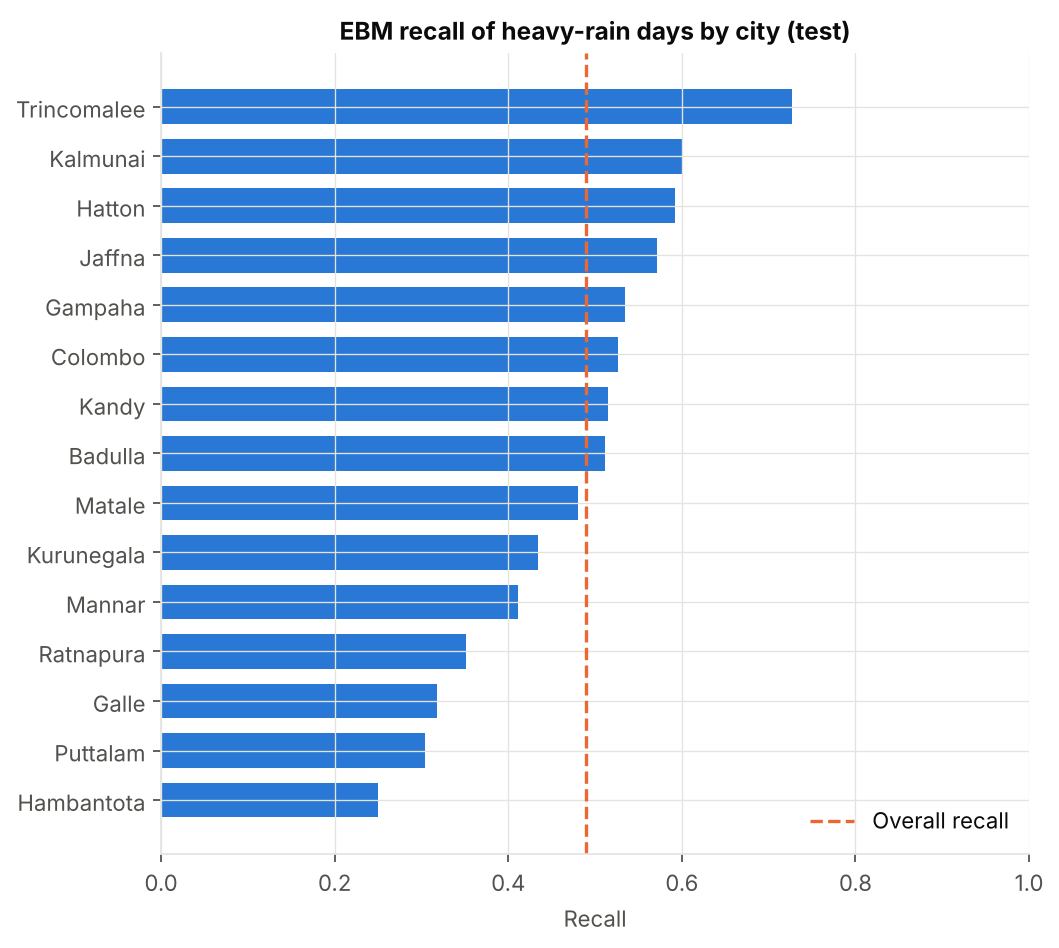

In [7]:
for f in ['roc_pr_curves.png', 'calibration.png', 'confusion_matrix.png', 'recall_by_city.png']:
    display(Image(FIG / f, width=750))

## 4. Explainability: EBM shape functions, SHAP, PDP, local explanations

In [8]:
explain.main()

/usr/local/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


{
  "ebm_term_importance": {
    "weathercode": 0.6863,
    "tmin": 0.2564,
    "rain_today": 0.2559,
    "wind_dir": 0.2489,
    "rain_yesterday": 0.2468,
    "rain_hours_today": 0.2432,
    "et0": 0.2261,
    "wind_max": 0.2126,
    "rain_14d": 0.2089,
    "rain_3d": 0.1848,
    "gust_max": 0.1736,
    "wet_days_7d": 0.1683,
    "rain_7d": 0.1503,
    "radiation": 0.133,
    "month": 0.126,
    "tmax": 0.1214,
    "gust_max & wind_dir": 0.1046,
    "feels_like_gap": 0.1037,
    "temp_range": 0.0979,
    "feels_like_gap & wind_dir": 0.0975,
    "rain_hours_today & gust_max": 0.0893,
    "elevation": 0.0831,
    "gust_max & month": 0.0788,
    "radiation_change & et0": 0.0662,
    "rain_today & gust_max": 0.0662,
    "rain_14d & radiation": 0.0661,
    "radiation_change": 0.0582,
    "rain_7d & radiation": 0.0568,
    "et0 & gust_max": 0.0541,
    "rain_hours_today & et0": 0.0535,
    "temp_range & wind_dir": 0.0509,
    "rain_7d & feels_like_gap": 0.0473,
    "tmean_change": 0.0435,
 

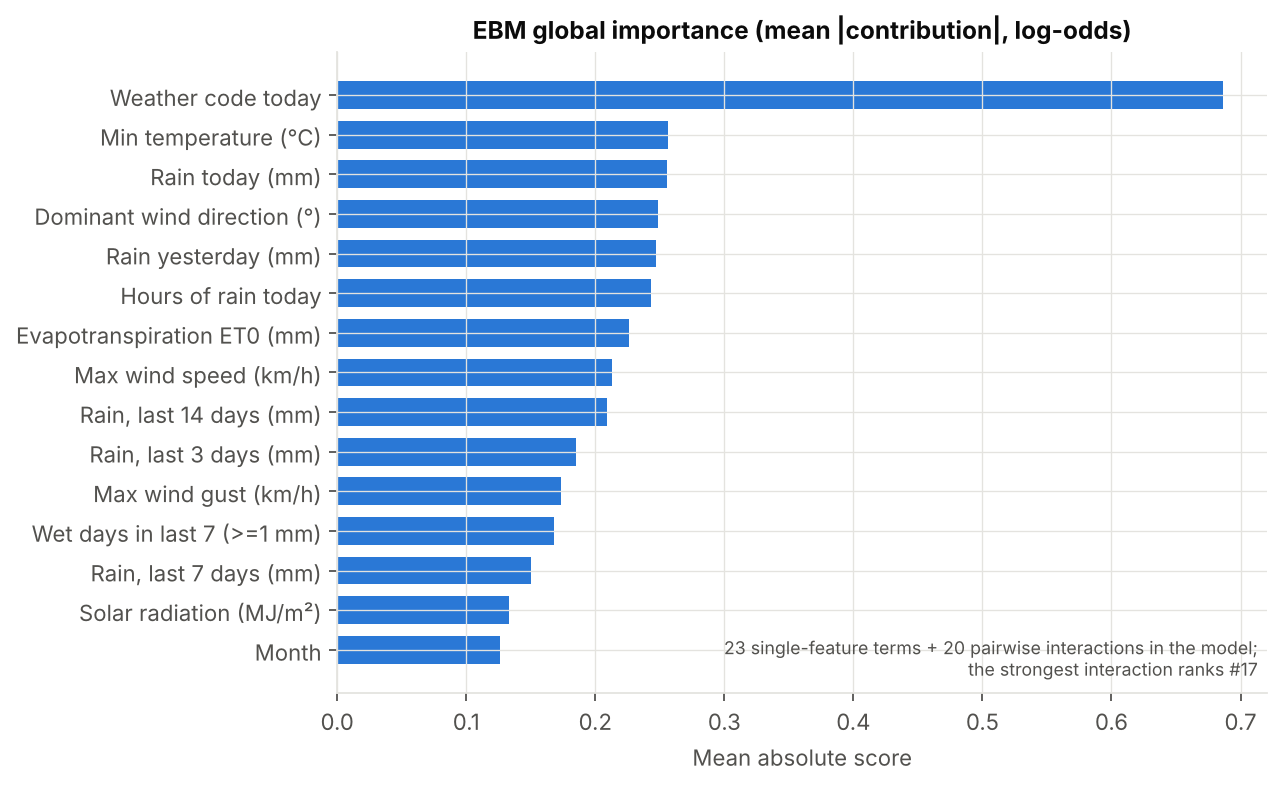

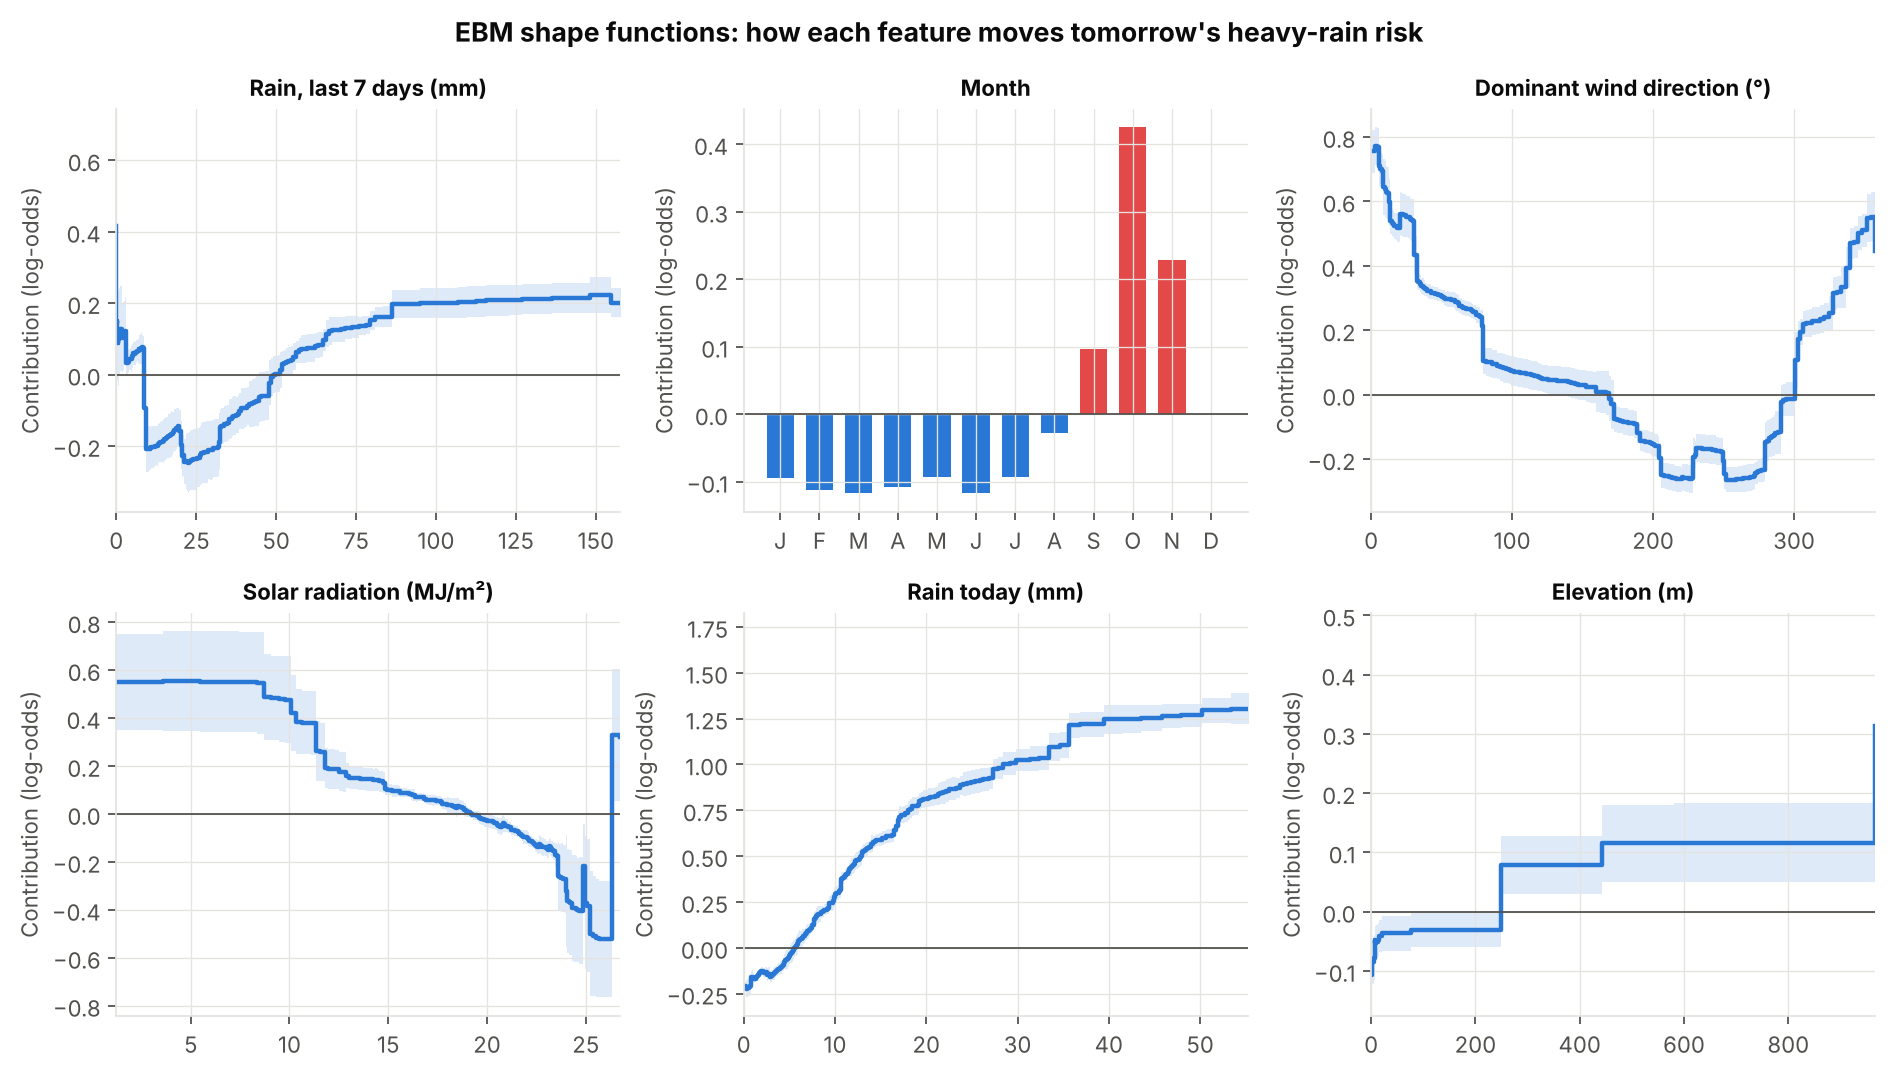

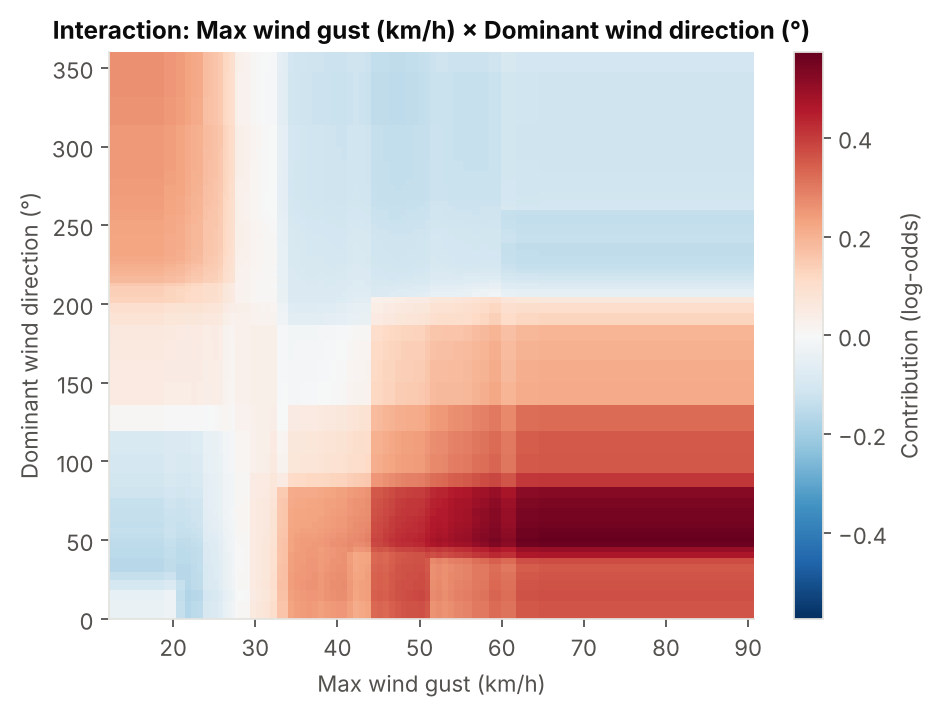

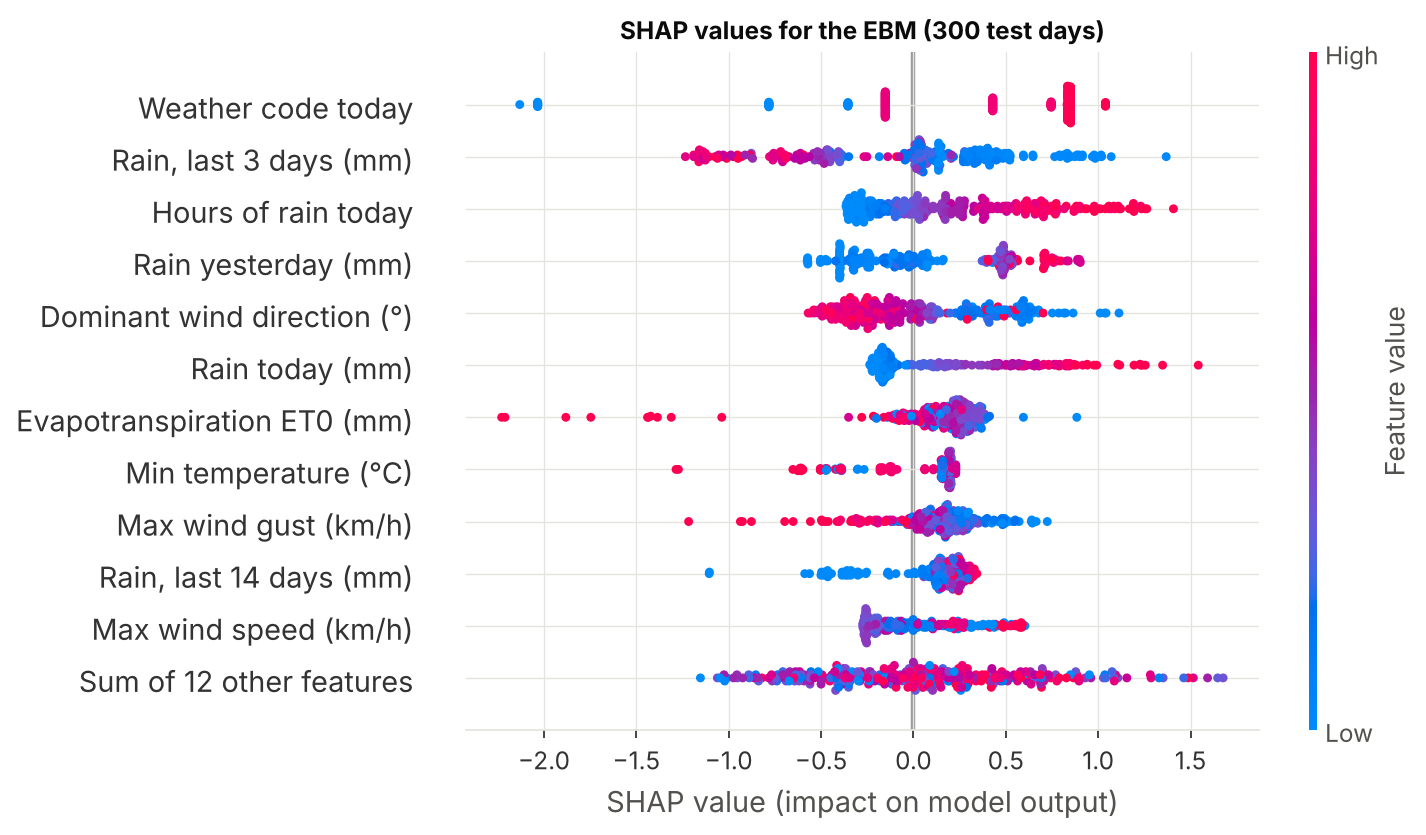

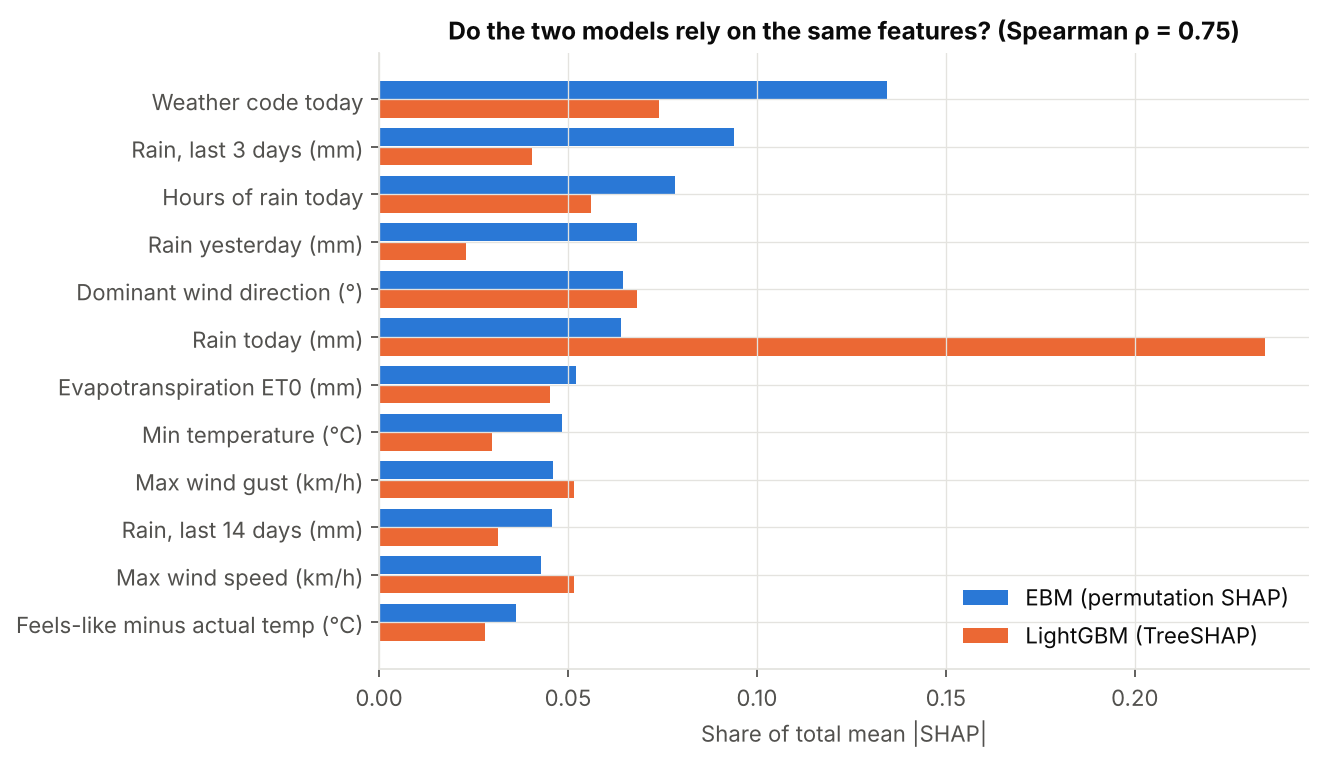

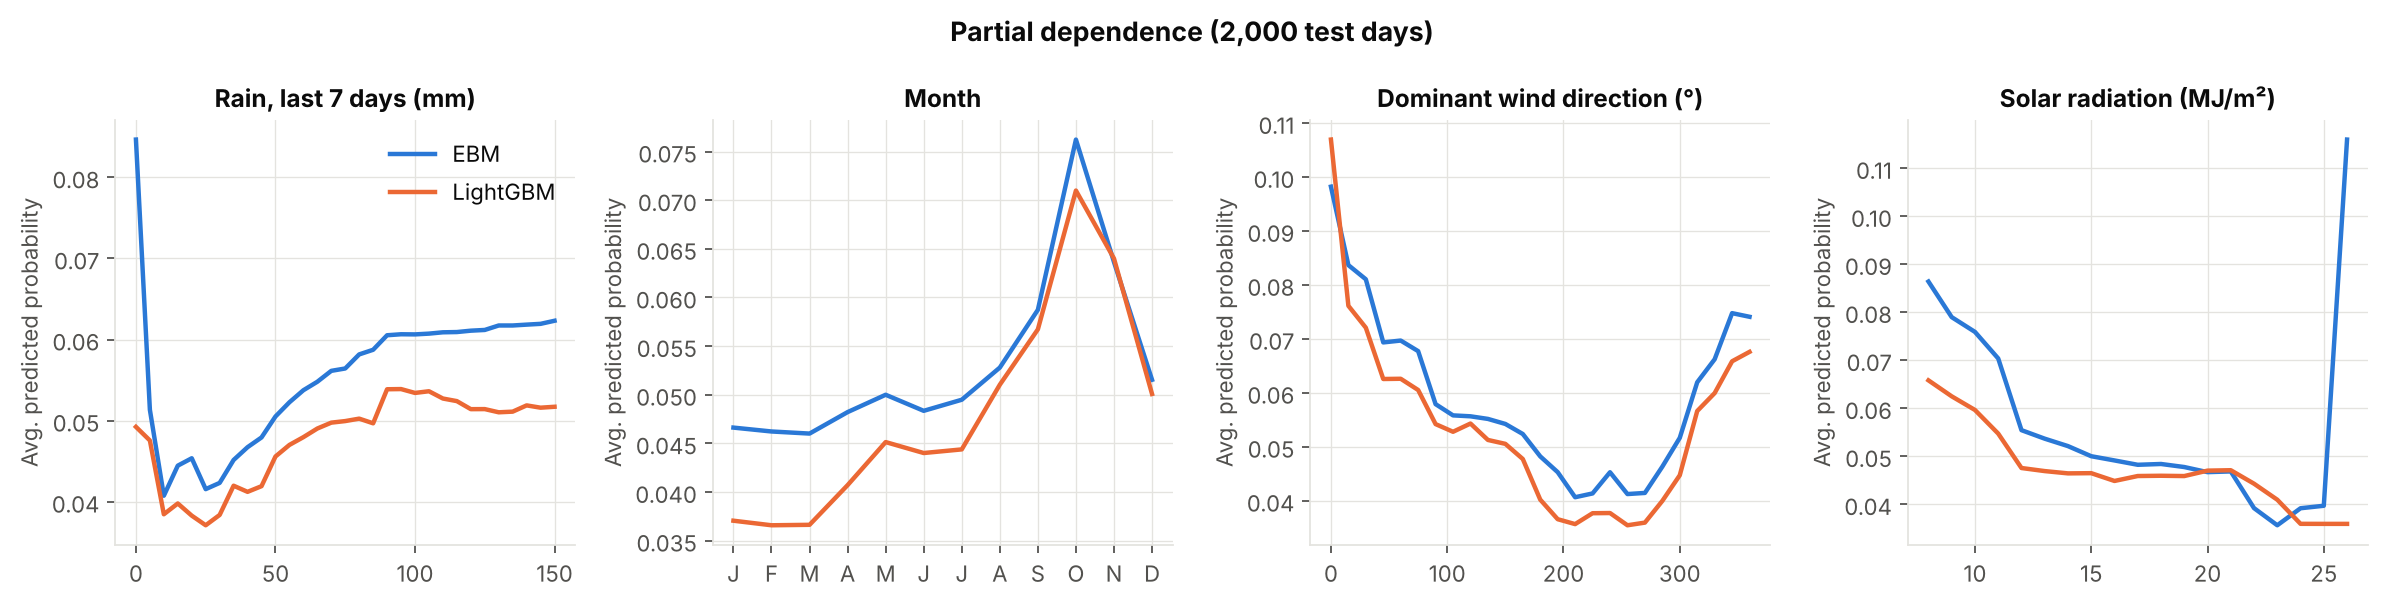

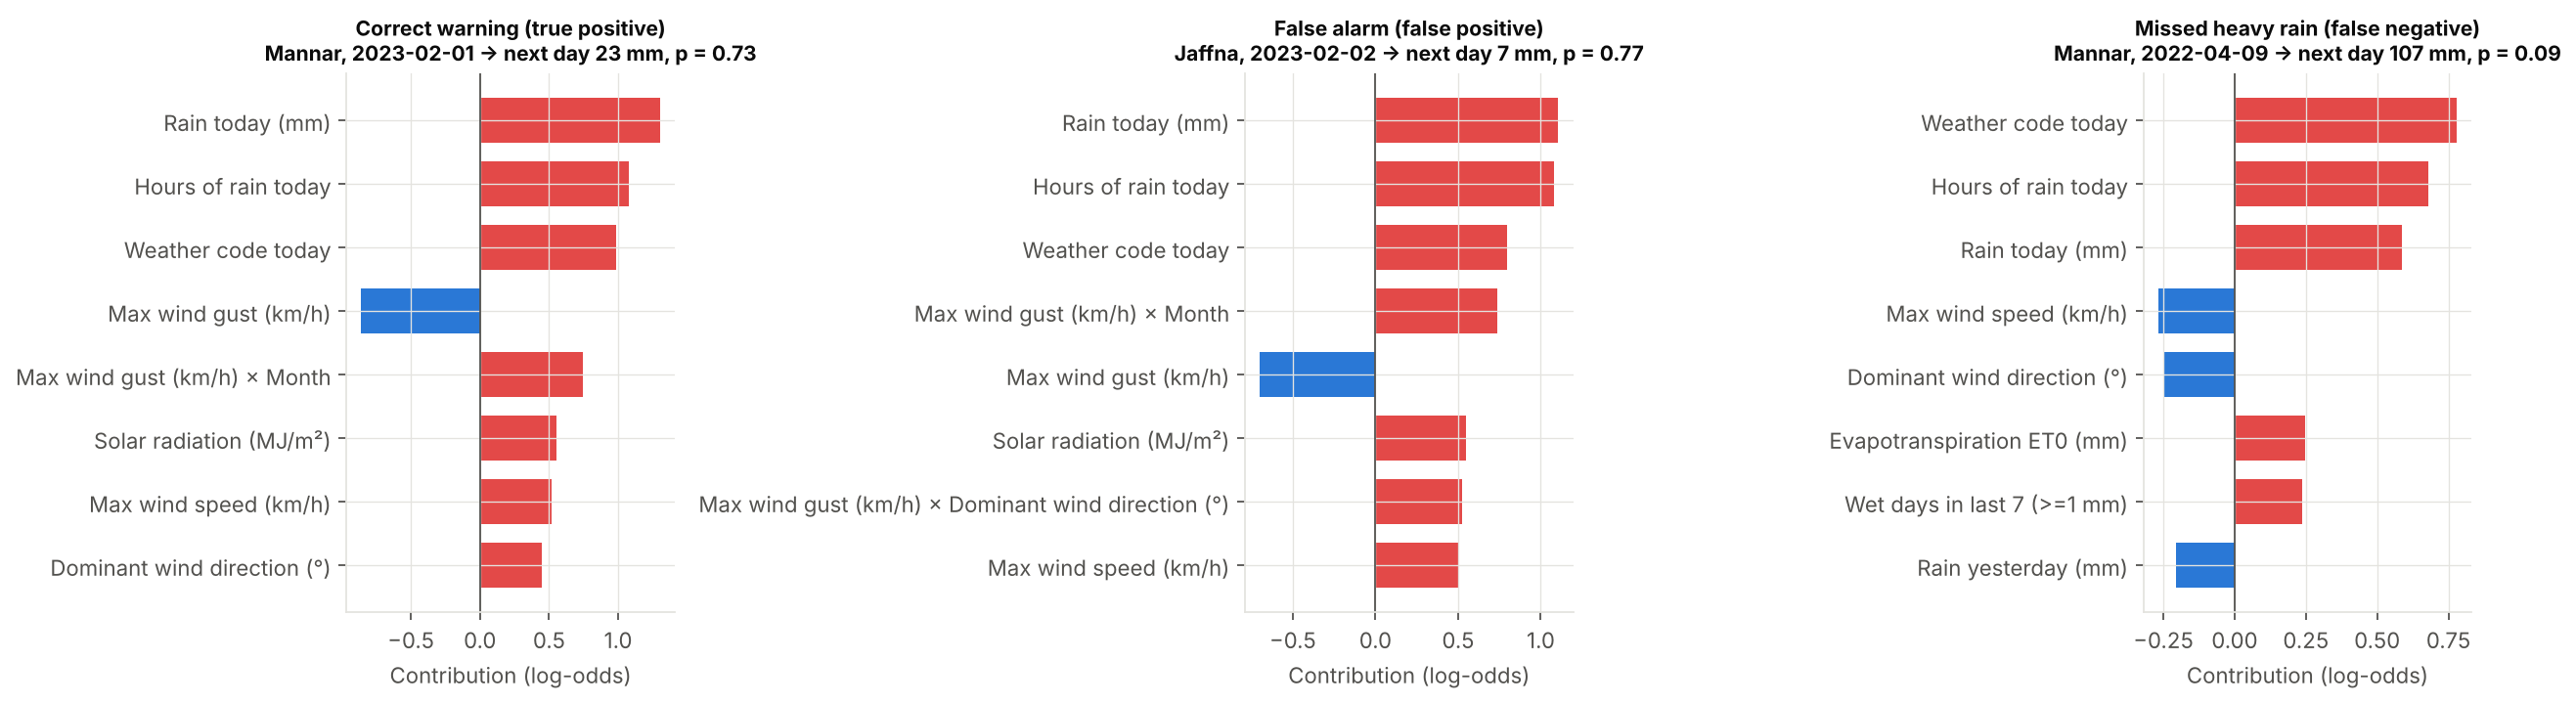

In [9]:
for f in ['ebm_global_importance.png', 'ebm_shape_functions.png', 'ebm_top_interaction.png', 'shap_beeswarm_ebm.png',
          'shap_ebm_vs_lightgbm.png', 'pdp_ebm_vs_lightgbm.png', 'local_explanations.png']:
    display(Image(FIG / f, width=900))

## 5. Package the model for the web app

In [10]:
export_app_assets.main()

App assets written to /home/claude/rainrisk/app/assets
